# 04 — Rede neural e avaliação offline

**Protocolo.** Para cada usuário, 5 leituras aleatórias formam o perfil (como se fossem as 5 últimas informadas) e as demais ficam escondidas. A rede aprende, a partir de perfil + segmento + livro, a probabilidade de o usuário **gostar** do livro (nota ≥ 4). Usuários de teste nunca participam do treino.

**Avaliação amostrada.** Para cada usuário de teste, o pool tem até 5 positivos escondidos (nota ≥ 4) + 99 livros não lidos. Todos os métodos ranqueiam **o mesmo pool**:

| Método | Score |
|---|---|
| aleatório | sorteio (piso) |
| (a) popularidade global | `ratings_count` |
| (b) popularidade por cluster | `cluster_score` = (perfil · probs do livro) × log1p(popularidade) |
| (c) sistema completo | probabilidade da rede neural |

Os negativos são sorteados **proporcionalmente à popularidade** (livros com ≥ 10 avaliações). Com sorteio uniforme, os negativos seriam quase todos obscuros e o baseline de popularidade ganharia trivialmente.

Entradas: artefatos dos notebooks 02 e 03. Saídas: `mlp.joblib`, `results.csv`, `figures/`.

In [1]:
import os
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from recsys import (cluster_score, hit_at_k, ndcg_at_k, pair_features, recall_at_k, recommend,
                    split_user, user_profile)

SEED, N_PROFILE, N_NEG, MAX_POS, TOP = 0, 5, 99, 5, 10
os.makedirs('figures', exist_ok=True)
inter = pd.read_parquet('user_interactions.parquet')
book_probs = pd.read_parquet('book_probs.parquet')
book_vec = pd.read_parquet('book_vectors.parquet')
meta = pd.read_parquet('book_meta.parquet')
user_pipe = joblib.load('gmm_users.joblib')
K = book_probs.shape[1]
assert book_vec.index.equals(book_probs.index) and list(book_vec.columns[-K:]) == list(book_probs.columns)
pop = meta['ratings_count'].fillna(0).reindex(book_probs.index)
print(f'{inter.user_id.nunique():,} usuários | {K} componentes de livro | {book_vec.shape[1]} features por livro')

50,000 usuários | 20 componentes de livro | 36 features por livro


### Divisão por usuário e perfis (a partir de 5 leituras)

In [2]:
rng = np.random.default_rng(SEED)
by_user = {u: (d['book_id'].to_numpy(), d['rating'].to_numpy()) for u, d in inter.groupby('user_id')}
users = np.array(sorted(by_user))
perm = rng.permutation(users)
n_test = int(0.2 * len(perm)); n_val = int(0.1 * (len(perm) - n_test))
test_u, val_u, train_u = perm[:n_test], perm[n_test:n_test + n_val], perm[n_test + n_val:]
print('treino', len(train_u), '| validação', len(val_u), '| teste', len(test_u))

def prep(u):
    ids, r = by_user[u]
    p_ids, p_r, h_ids, h_r = split_user(ids, r, seed=int(u))
    return dict(profile=user_profile(book_probs, p_ids.tolist(), p_r.tolist()),
                read=set(ids.tolist()), h_ids=h_ids, h_r=h_r)

P = {u: prep(u) for u in users}
profiles = np.vstack([P[u]['profile'] for u in users])
segs = user_pipe.predict_proba(profiles)
for u, s in zip(users, segs):
    P[u]['seg'] = s
print('perfis prontos')

treino 36000 | validação 4000 | teste 10000


perfis prontos


### Negativos: livros não lidos, proporcionais à popularidade

In [3]:
cat_mask = (pop >= 10).to_numpy()
cat_ids = book_probs.index.to_numpy()[cat_mask]
cdf = np.cumsum(pop.to_numpy()[cat_mask]); cdf /= cdf[-1]

def sample_unread(rng, read, n):
    out, seen = [], set(read)
    while len(out) < n:
        for b in cat_ids[np.searchsorted(cdf, rng.random(3 * n))].tolist():
            if b not in seen:
                seen.add(b); out.append(b)
                if len(out) == n:
                    break
    return np.array(out)

print(f'catálogo de negativos: {len(cat_ids):,} livros')

catálogo de negativos: 1,543,759 livros


### Pares de treino/validação

Positivos: escondidos com nota ≥ 4 (até 10 por usuário). Negativos (mesma quantidade): escondidos com nota ≤ 3 primeiro, completando com livros não lidos.

In [4]:
vec_np = book_vec.to_numpy(dtype='float32')
row_of = pd.Series(np.arange(len(book_vec)), index=book_vec.index)

def make_pairs(user_list, rng):
    X, y = [], []
    for u in user_list:
        d = P[u]
        pos = d['h_ids'][d['h_r'] >= 4]
        if len(pos) == 0:
            continue
        pos = rng.permutation(pos)[:10]
        low = rng.permutation(d['h_ids'][d['h_r'] <= 3])[:len(pos)]
        neg = np.concatenate([low, sample_unread(rng, d['read'], len(pos) - len(low))]) if len(low) < len(pos) else low
        ids = np.concatenate([pos, neg]).astype(book_vec.index.dtype)
        X.append(pair_features(d['profile'], d['seg'], vec_np[row_of.loc[ids].to_numpy()]))
        y.append(np.r_[np.ones(len(pos)), np.zeros(len(neg))])
    return np.vstack(X).astype('float32'), np.concatenate(y)

Xtr, ytr = make_pairs(train_u, rng)
Xva, yva = make_pairs(val_u, rng)
print(Xtr.shape, f'positivos: {ytr.mean():.1%}', '|', Xva.shape)

(715972, 69) positivos: 50.0% | (79612, 69)


### Treino da rede neural (MLP)

épocas: 10 | AUC (usuários de validação): 0.675


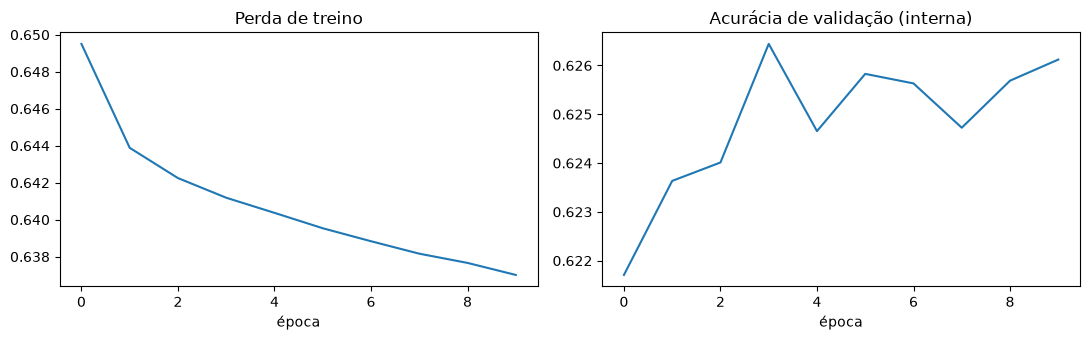

['mlp.joblib']

In [5]:
model = make_pipeline(StandardScaler(),
                      MLPClassifier(hidden_layer_sizes=(128, 64), early_stopping=True, n_iter_no_change=5,
                                    max_iter=60, random_state=SEED))
model.fit(Xtr, ytr)
mlp = model[-1]
auc = roc_auc_score(yva, model.predict_proba(Xva)[:, 1])
print(f'épocas: {mlp.n_iter_} | AUC (usuários de validação): {auc:.3f}')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(mlp.loss_curve_); ax[0].set(title='Perda de treino', xlabel='época')
ax[1].plot(mlp.validation_scores_); ax[1].set(title='Acurácia de validação (interna)', xlabel='época')
plt.tight_layout(); plt.savefig('figures/curva_rede.png', dpi=150); plt.show()
joblib.dump(model, 'mlp.joblib')

### Avaliação nos usuários de teste

In [6]:
rows = {m: {'hit': [], 'recall': [], 'ndcg': []} for m in ['aleatório', 'popularidade global', 'popularidade por cluster', 'rede neural (sistema completo)']}
erng = np.random.default_rng(SEED + 1)
n_eval = 0
for u in test_u:
    d = P[u]
    pos = d['h_ids'][d['h_r'] >= 4]
    if len(pos) == 0:
        continue
    pos = erng.permutation(pos)[:MAX_POS]
    pool = np.concatenate([pos, sample_unread(erng, d['read'], N_NEG)])
    pool = erng.permutation(pool)               # embaralha: empates não podem favorecer os positivos
    posset = set(pos.tolist())
    pool_probs = book_probs.loc[pool].to_numpy()
    pool_pop = pop.loc[pool].to_numpy()
    scores = {
        'aleatório': erng.random(len(pool)),
        'popularidade global': pool_pop,
        'popularidade por cluster': cluster_score(d['profile'], pool_probs, pool_pop),
        'rede neural (sistema completo)': model.predict_proba(
            pair_features(d['profile'], d['seg'], vec_np[row_of.loc[pool].to_numpy()]))[:, 1],
    }
    for m, s in scores.items():
        ranked = pool[np.argsort(-s, kind='stable')].tolist()
        rows[m]['hit'].append(hit_at_k(ranked, posset, TOP))
        rows[m]['recall'].append(recall_at_k(ranked, posset, TOP))
        rows[m]['ndcg'].append(ndcg_at_k(ranked, posset, TOP))
    n_eval += 1

def ci(a):
    a = np.asarray(a, dtype=float); return 1.96 * a.std(ddof=1) / np.sqrt(len(a))

res = pd.DataFrame({m: {'Hit@10': np.mean(v['hit']), 'Recall@10': np.mean(v['recall']), 'NDCG@10': np.mean(v['ndcg']),
                        'IC95 NDCG@10 (±)': ci(v['ndcg']), 'usuários': n_eval} for m, v in rows.items()}).T
res.to_csv('results.csv')
print(f'{n_eval:,} usuários avaliados | pool = até {MAX_POS} positivos + {N_NEG} negativos')
res.round(3)

9,998 usuários avaliados | pool = até 5 positivos + 99 negativos


,Hit@10,Recall@10,NDCG@10,IC95 NDCG@10 (±),usuários
aleatório,0.404,0.096,0.074,0.002,9998.0
popularidade global,0.469,0.148,0.124,0.003,9998.0
popularidade por cluster,0.728,0.293,0.240,0.004,9998.0
rede neural (sistema completo),0.738,0.270,0.227,0.004,9998.0


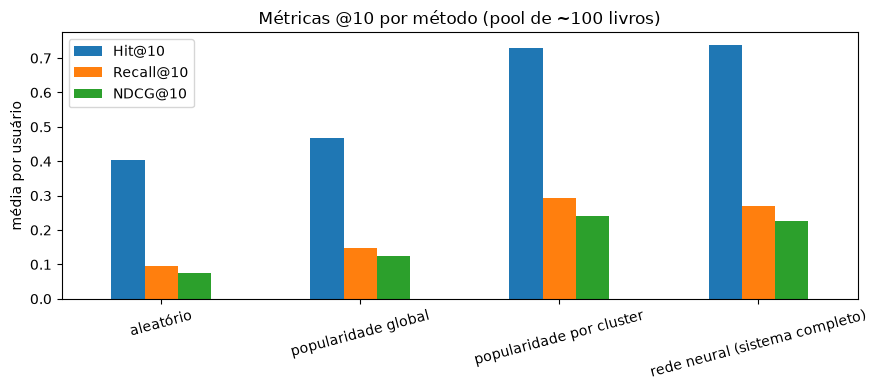

piso esperado (aleatório) Hit@10 ≈ 0.403 para 5 positivos em 104


In [7]:
res[['Hit@10', 'Recall@10', 'NDCG@10']].plot.bar(figsize=(9, 4), rot=15, title='Métricas @10 por método (pool de ~100 livros)')
plt.ylabel('média por usuário'); plt.tight_layout(); plt.savefig('figures/metricas.png', dpi=150); plt.show()
print('piso esperado (aleatório) Hit@10 ≈', round(1 - np.prod([(N_NEG - i) / (N_NEG + MAX_POS - i) for i in range(TOP)]), 3), 'para 5 positivos em 104')

### Exemplos qualitativos

Pipeline real: 5 leituras → perfil → candidatos do GMM (200) → reordenação pela rede → top 10, sobre **todo** o catálogo.

In [8]:
for u in test_u[:3]:
    ids, r = by_user[u]
    p_ids, p_r, _, _ = split_user(ids, r, seed=int(u))
    recs = recommend(p_ids.tolist(), p_r.tolist(), book_probs, pop, user_pipe, model, book_vec, top_n=TOP, n_candidates=200)
    print(f'=== usuário {u} | segmento {P[u]["seg"].argmax()} ===')
    print('Leituras informadas:')
    print(meta.loc[p_ids, ['title', 'name']].assign(nota=p_r).to_string(index=False))
    print('Recomendações:')
    print(meta.loc[recs, ['title', 'name', 'ratings_count', 'average_rating']].to_string(index=False), '\n')

=== usuário 335815 | segmento 8 ===
Leituras informadas:


                                                                     title                  name  nota
                            A Game of Thrones (A Song of Ice and Fire, #1)    George R.R. Martin     5
                               Revolution 2020: Love, Corruption, Ambition         Chetan Bhagat     2
                         The Universe Doesn't Give a Flying Fuck About You      Johnny B. Truant     4
Fooled by Randomness: The Hidden Role of Chance in Life and in the Markets Nassim Nicholas Taleb     4
                                                             The Alchemist          Paulo Coelho     4
Recomendações:
                                                      title                     name  ratings_count  average_rating
              Just Mercy: A Story of Justice and Redemption          Bryan Stevenson        30164.0            4.59
              Jesus Calling: Enjoying Peace in His Presence             Sarah  Young        35891.0            4.54
                   

=== usuário 76729 | segmento 10 ===
Leituras informadas:
                                 title          name  nota
Enemy From The Past (Unseen Enemy, #4) Marysol James     5
        Wrong (Breaking the Rules, #2)   K.  Webster     5
         Bright Side (Bright Side, #1)    Kim Holden     5
             Knox: Volume 4 (Knox, #4)    Cassia Leo     5
                       Bait (Wake, #1)      M. Mabie     5
Recomendações:
                                title              name  ratings_count  average_rating
                 Crashed (Driven, #3)       K. Bromberg        32661.0            4.56
   Rock Chick Regret (Rock Chick, #7)    Kristen Ashley        25292.0            4.55
                  Fueled (Driven, #2)       K. Bromberg        37842.0            4.51
  Rock Chick Revenge (Rock Chick, #5)    Kristen Ashley        27381.0            4.50
                       Archer's Voice      Mia Sheridan        53467.0            4.45
 Rock Chick Renegade (Rock Chick, #4)    Kristen Ash

=== usuário 135971 | segmento 8 ===
Leituras informadas:
                                                                                             title             name  nota
                                                                                      The Red Tent    Anita Diamant     5
                                                                                            Lolita Vladimir Nabokov     4
The Year of Living Biblically: One Man's Humble Quest to Follow the Bible as Literally as Possible      A.J. Jacobs     3
                                                                                         The Stand     Stephen King     3
                                                                               Pride and Prejudice      Jane Austen     5
Recomendações:
                                          title             name  ratings_count  average_rating
                                The Nightingale   Kristin Hannah       271556.0            4.54
    